In [47]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"001 Bank Customer Churn Prediction.csv")

In [3]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.shape

(10000, 12)

In [5]:
df.columns.tolist()

['customer_id',
 'credit_score',
 'country',
 'gender',
 'age',
 'tenure',
 'balance',
 'products_number',
 'credit_card',
 'active_member',
 'estimated_salary',
 'churn']

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [7]:
df.describe()

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [8]:
df.duplicated().sum()

0

In [9]:
df["churn"].value_counts()

0    7963
1    2037
Name: churn, dtype: int64

In [10]:
df.drop(columns = ["customer_id", "products_number"] , axis = 'columns', inplace = True)

In [11]:
df.head()

,credit_score,country,gender,age,tenure,balance,credit_card,active_member,estimated_salary,churn
0,619,France,Female,42,2,0.00,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,1,0,113931.57,1
3,699,France,Female,39,1,0.00,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,79084.10,0


In [12]:
from sklearn.preprocessing import LabelEncoder

In [13]:
le = LabelEncoder()

In [14]:
columns = ["country", 'gender']

In [15]:
df[columns] = df[columns].apply(le.fit_transform)

In [16]:
df.head(1)

,credit_score,country,gender,age,tenure,balance,credit_card,active_member,estimated_salary,churn
0,619,0,0,42,2,0.0,1,1,101348.88,1


In [17]:
# Now before procedding to scaling, let's first split predictor and class variable

x = df.iloc[:, 0:9]
y = df.churn

In [18]:
x.head()

,credit_score,country,gender,age,tenure,balance,credit_card,active_member,estimated_salary
0,619,0,0,42,2,0.00,1,1,101348.88
1,608,2,0,41,1,83807.86,0,1,112542.58
2,502,0,0,42,8,159660.80,1,0,113931.57
3,699,0,0,39,1,0.00,0,0,93826.63
4,850,2,0,43,2,125510.82,1,1,79084.10


In [19]:
y.head()

0    1
1    0
2    1
3    0
4    0
Name: churn, dtype: int64

In [20]:
x.dtypes

credit_score          int64
country               int32
gender                int32
age                   int64
tenure                int64
balance             float64
credit_card           int64
active_member         int64
estimated_salary    float64
dtype: object

In [21]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()

In [22]:
x = ss.fit_transform(x)

In [23]:
x[0]

array([-0.32622142, -0.90188624, -1.09598752,  0.29351742, -1.04175968,
       -1.22584767,  0.64609167,  0.97024255,  0.02188649])

In [24]:
y[0]

1

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [27]:
x_train[0]

array([-0.27448754,  0.30659057, -1.09598752,  0.10281024, -0.69598177,
        1.17760946,  0.64609167, -1.03067011,  0.07860907])

In [28]:
x_train.shape

(8000, 9)

In [29]:
y_train.shape

(8000,)

In [90]:
import tensorflow
from tensorflow import keras

# We can build two types of models in Keras; Sequential and Non-Sequential
# Here we will go with Sequential
from keras import Sequential
from keras.layers import Dense

In [91]:
model = Sequential()

In [92]:
model.add(Dense(3, activation = 'relu', input_dim = 9)) # imput_dimensions refers to no.of input i.e no of columns
model.add(Dense(3, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [93]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 3)                 30        
                                                                 
 dense_4 (Dense)             (None, 3)                 12        
                                                                 
 dense_5 (Dense)             (None, 1)                 4         
                                                                 
Total params: 46 (184.00 Byte)
Trainable params: 46 (184.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [94]:
model.compile(loss = 'binary_crossentropy', optimizer = "Adam", metrics = 'accuracy')

In [95]:
history = model.fit(x_train, y_train, epochs = 10, validation_split = 0.2)

Epoch 1/10
200/200 [==============================] - 1s 3ms/step - loss: 0.5124 - accuracy: 0.7984 - val_loss: 0.4789 - val_accuracy: 0.7925
Epoch 2/10
200/200 [==============================] - 0s 2ms/step - loss: 0.4635 - accuracy: 0.7984 - val_loss: 0.4610 - val_accuracy: 0.7925
Epoch 3/10
200/200 [==============================] - 0s 2ms/step - loss: 0.4492 - accuracy: 0.7984 - val_loss: 0.4545 - val_accuracy: 0.7925
Epoch 4/10
200/200 [==============================] - 1s 3ms/step - loss: 0.4419 - accuracy: 0.7984 - val_loss: 0.4510 - val_accuracy: 0.7925
Epoch 5/10
200/200 [==============================] - 0s 2ms/step - loss: 0.4377 - accuracy: 0.7984 - val_loss: 0.4490 - val_accuracy: 0.7925
Epoch 6/10
200/200 [==============================] - 1s 3ms/step - loss: 0.4346 - accuracy: 0.7984 - val_loss: 0.4481 - val_accuracy: 0.7925
Epoch 7/10
200/200 [==============================] - 1s 3ms/step - loss: 0.4325 - accuracy: 0.7984 - val_loss: 0.4477 - val_accuracy: 0.7925
Epoch 

In [96]:
model.layers[0].get_weights()

[array([[-0.15292516,  0.1092759 ,  0.38986593],
        [ 0.42612687, -0.76390606,  0.20801677],
        [ 0.10485311,  0.2618556 ,  0.46121582],
        [-0.84767926, -0.92871344, -0.88998204],
        [ 0.3602655 ,  0.00317794, -0.64538985],
        [-0.45420244,  0.1989933 , -0.8798426 ],
        [ 0.14208259, -0.1274051 ,  0.12227619],
        [-0.05081431,  0.18148798,  0.79487807],
        [-0.36077753,  0.03930596,  0.50014657]], dtype=float32),
 array([0.26088002, 0.50116074, 0.5282572 ], dtype=float32)]

In [97]:
y_log = model.predict(x_test)

63/63 [==============================] - 0s 1ms/step


In [98]:
y_log[0:5]

array([[0.0763241 ],
       [0.22977866],
       [0.09089185],
       [0.44931775],
       [0.13426335]], dtype=float32)

In [99]:
pred = np.where(y_log>0.3,1,0) 

In [100]:
pred[0:6]

array([[0],
       [0],
       [0],
       [1],
       [0],
       [1]])

In [101]:
from sklearn.metrics import accuracy_score

In [102]:
accuracy = accuracy_score(pred, y_test)

In [103]:
accuracy

0.755

# Plotting of Training and Validation loss

In [104]:
import matplotlib.pyplot as plt

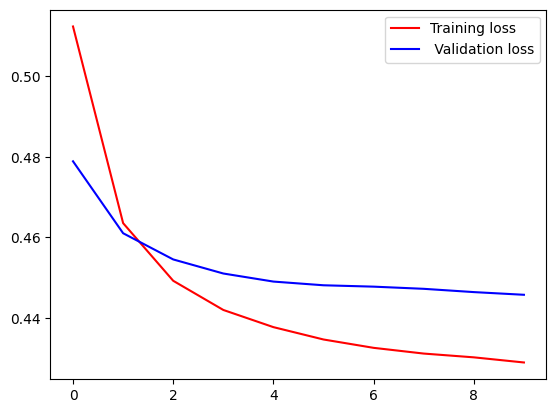

In [105]:
plt.plot(history.history['loss'], color = 'red', label = 'Training loss')
plt.plot(history.history['val_loss'], color = 'blue', label = ' Validation loss')
plt.legend()

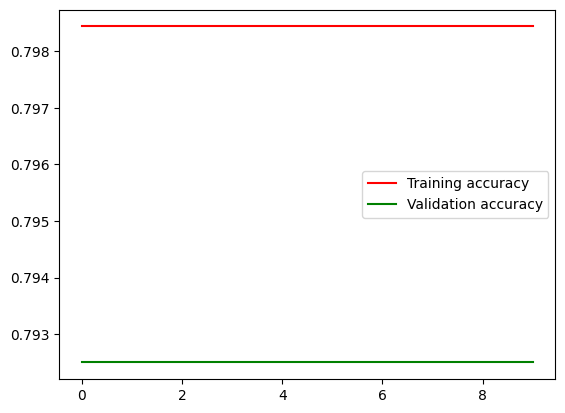

In [106]:
plt.plot(history.history['accuracy'], color = 'red', label = 'Training accuracy')
plt.plot(history.history['val_accuracy'], color = 'green', label = 'Validation accuracy')
plt.legend()

In [88]:
filter_ylog = y_log[y_log >= 0.3]

In [89]:
filter_ylog

array([0.4139311 , 0.39607432, 0.4139311 , 0.4139311 , 0.33301863,
       0.35232142, 0.4139311 , 0.31606   , 0.30534312, 0.4139311 ,
       0.4139311 , 0.318305  , 0.36746594, 0.32711592, 0.40527192,
       0.4139311 , 0.4139311 , 0.34191716, 0.4139311 , 0.4139311 ,
       0.32147738, 0.32120088, 0.38801178, 0.39027408, 0.33033782,
       0.4139311 , 0.4139311 , 0.40678275, 0.4114433 , 0.3292531 ,
       0.4139311 , 0.4139311 , 0.39828932, 0.4139311 , 0.4139311 ,
       0.34107268, 0.37824485, 0.39767855, 0.4139311 , 0.4139311 ,
       0.3272245 , 0.4139311 , 0.34385762, 0.4139311 , 0.38235554,
       0.4139311 , 0.3465366 , 0.4052167 , 0.4139311 , 0.4139311 ,
       0.3652648 , 0.361425  , 0.38165486, 0.372962  , 0.32155472,
       0.4139311 , 0.3057616 , 0.4139311 , 0.4139311 , 0.3576629 ,
       0.3711484 , 0.4139311 , 0.40968823, 0.30455053, 0.4139311 ,
       0.4139311 , 0.31464615, 0.4139311 , 0.4139311 , 0.36902004,
       0.4139311 , 0.35860345, 0.4139311 , 0.4139311 , 0.35172

In [108]:
indices = np.where(y_log>=0.3)

In [113]:
indices

(array([   3,    5,    7,   11,   23,   25,   26,   37,   39,   41,   45,
          46,   48,   54,   56,   62,   69,   80,   83,   84,   90,   93,
          98,  103,  113,  114,  115,  126,  131,  139,  143,  149,  153,
         154,  155,  156,  167,  169,  170,  174,  179,  180,  181,  184,
         185,  186,  191,  194,  197,  202,  204,  205,  213,  215,  221,
         225,  228,  231,  234,  238,  242,  243,  248,  251,  252,  253,
         264,  268,  269,  270,  271,  272,  274,  275,  282,  285,  290,
         292,  296,  309,  316,  319,  321,  323,  324,  329,  331,  335,
         336,  356,  357,  359,  360,  366,  367,  368,  369,  371,  374,
         380,  381,  382,  384,  385,  393,  396,  397,  398,  400,  402,
         405,  406,  412,  415,  418,  421,  433,  436,  439,  440,  444,
         446,  449,  454,  460,  479,  484,  486,  489,  493,  501,  510,
         513,  514,  516,  517,  520,  521,  527,  530,  548,  554,  556,
         559,  562,  564,  565,  568, 